In [1]:
import sys
import torch
import tensorflow as tf
import numpy as np

print("=" * 50)
print("ENVIRONMENT INFORMATION")
print("=" * 50)

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("NumPy:", np.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

ENVIRONMENT INFORMATION
Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
TensorFlow: 2.21.0
PyTorch: 2.11.0+cpu
CUDA version: None
NumPy: 2.4.6
GPU available: False


In [2]:
%pip install onnxruntime==1.20.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 46.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [onnxruntime]


In [3]:
#%pip list

In [4]:
!pip install onnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 43.3 MB/s  0:00:00


In [5]:
!pip install onnx2torch

In [6]:
!pip install -Uqq tf2onnx

In [7]:
import os
import copy
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import onnx
import tf2onnx
from onnx2torch import convert as onnx2torch_convert

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import sklearn
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, balanced_accuracy_score,
    roc_curve, precision_recall_curve,
    auc as sklearn_auc
)

print(f"PyTorch       : {torch.__version__}")
print(f"ONNX          : {onnx.__version__}")
print(f"tf2onnx       : {tf2onnx.__version__}")
print(f"scikit-learn  : {sklearn.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device  : {DEVICE}")

PyTorch       : 2.11.0+cpu
ONNX          : 1.23.2
tf2onnx       : 1.17.0
scikit-learn  : 1.6.1
CUDA available: False
Using device  : cpu


In [8]:
# ── Adjust BASE_DIR to your environment ──────────────────────────────────────
# Google Colab with Google Drive:
#   BASE_DIR = '/content/drive/MyDrive/MSDeepAMR'
# Local machine:
#   BASE_DIR = os.path.expanduser('~/Documents/deepAMR/DL-AMR')

BASE_DIR  = '/content/drive/MyDrive/MSDeepAMR'
C2018_DIR = os.path.join(BASE_DIR, 'data', 'C2018')
ONNX_DIR  = os.path.join(BASE_DIR, 'onnx_models')  # ONNX exports stored here
PT_DIR    = os.path.join(BASE_DIR, 'pt_models')     # fine-tuned .pt files saved here

os.makedirs(ONNX_DIR, exist_ok=True)
os.makedirs(PT_DIR,   exist_ok=True)

# ── Pretrained Keras model files (284 MB each) ───────────────────────────────
H5_MODELS = {
    'e_coli_ceftriaxone'     : os.path.join(BASE_DIR, 'e_coli_ceftriaxone.h5'),
    'k_pneumoniae_ceftriaxone': os.path.join(BASE_DIR, 'k_pneumoniae_ceftriaxone.h5'),
    's_aureus_oxacillin'     : os.path.join(BASE_DIR, 's_aureus_oxacillin.h5'),
}

MODEL_META = {
    'e_coli_ceftriaxone'     : {'species': 'Escherichia coli',     'drug': 'Ceftriaxone'},
    'k_pneumoniae_ceftriaxone': {'species': 'Klebsiella pneumoniae','drug': 'Ceftriaxone'},
    's_aureus_oxacillin'     : {'species': 'Staphylococcus aureus', 'drug': 'Oxacillin'},
}

print("Paths configured:")
for name, path in H5_MODELS.items():
    status = '✓' if os.path.exists(path) else '✗ NOT FOUND'
    print(f"  [{status}]  {name}")

Paths configured:
  [✓]  e_coli_ceftriaxone
  [✓]  k_pneumoniae_ceftriaxone
  [✓]  s_aureus_oxacillin


In [9]:
# ── Learning rates (matching the TF notebook) ─────────────────────────────────
LR_FULL_FINETUNE    = 1e-5   # all layers unfrozen
LR_PARTIAL_UNFREEZE = 5e-6   # conv blocks 3 & 4 + dense head unfrozen

# ── Training schedule ────────────────────────────────────────────────────────
EPOCHS_FINETUNE = 50         # upper bound; EarlyStopping cuts this short
BATCH_SIZE      = 10
PATIENCE        = 5          # EarlyStopping patience (epochs)
LR_PATIENCE     = 3          # ReduceLROnPlateau patience
LR_FACTOR       = 0.1        # LR reduction factor
MIN_LR          = 1e-7

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── Result accumulator ───────────────────────────────────────────────────────
ALL_RESULTS = []

In [10]:
import os
import shutil
import subprocess
import tensorflow as tf

OPSET = 13   # ONNX opset version — 13 gives best coverage for Conv1D + BatchNorm

ONNX_PATHS = {}

for model_name, h5_path in H5_MODELS.items():
    onnx_path = os.path.join(ONNX_DIR, f"{model_name}.onnx")
    ONNX_PATHS[model_name] = onnx_path

    if os.path.exists(onnx_path):
        print(f"[SKIP] {model_name}.onnx already exists — skipping conversion.")
        continue

    print(f"\n[Converting] {model_name} ...")

    # Load Keras model
    keras_model = tf.keras.models.load_model(h5_path, compile=False)

    # To avoid 'keras_tensor' KeyErrors, export to a temporary SavedModel
    temp_saved_model_dir = os.path.join(ONNX_DIR, f"temp_{model_name}_saved_model")

    # Use standard channels-last input signature
    input_signature = [
        tf.TensorSpec(
            shape=(None, 6000, 1),
            dtype=tf.float32,
            name='input'
        )
    ]

    @tf.function(input_signature=input_signature)
    def serving_fn(x):
        return keras_model(x, training=False)

    # Save the concrete function signature
    tf.saved_model.save(
        keras_model,
        temp_saved_model_dir,
        signatures={'serving_default': serving_fn}
    )

    # Convert from SavedModel using the tf2onnx CLI via subprocess.
    # This is much more robust and avoids Python API version mismatches.
    cmd = [
        "python", "-m", "tf2onnx.convert",
        "--saved-model", temp_saved_model_dir,
        "--output", onnx_path,
        "--opset", str(OPSET)
    ]

    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(f"[ERROR] Conversion failed for {model_name}:")
        print(result.stderr)
    else:
        print(f"  Saved → {onnx_path}")

    # Clean up the temporary SavedModel directory
    if os.path.exists(temp_saved_model_dir):
        shutil.rmtree(temp_saved_model_dir)

    # Free Keras model from memory before next iteration
    del keras_model
    tf.keras.backend.clear_session()

[SKIP] e_coli_ceftriaxone.onnx already exists — skipping conversion.
[SKIP] k_pneumoniae_ceftriaxone.onnx already exists — skipping conversion.
[SKIP] s_aureus_oxacillin.onnx already exists — skipping conversion.


In [11]:
import onnx

for model_name, onnx_path in ONNX_PATHS.items():
    model_proto = onnx.load(onnx_path)
    try:
        onnx.checker.check_model(model_proto)
        print(f"[OK]  {model_name} — graph is valid, {len(model_proto.graph.node)} nodes")
    except onnx.checker.ValidationError as e:
        print(f"[FAIL] {model_name} — {e}")

[OK]  e_coli_ceftriaxone — graph is valid, 49 nodes
[OK]  k_pneumoniae_ceftriaxone — graph is valid, 49 nodes
[OK]  s_aureus_oxacillin — graph is valid, 49 nodes


In [12]:
from onnx2torch import convert as onnx2torch_convert

PT_MODELS = {}  # model_name → nn.Module on DEVICE

for model_name, onnx_path in ONNX_PATHS.items():
    print(f"Loading {model_name} ...")
    onnx_proto   = onnx.load(onnx_path)
    torch_model  = onnx2torch_convert(onnx_proto)
    torch_model  = torch_model.to(DEVICE)
    torch_model.eval()  # start in eval mode (inference default)

    PT_MODELS[model_name] = torch_model

    # Count parameters
    total  = sum(p.numel() for p in torch_model.parameters())
    print(f"  Parameters : {total:,}")

Loading e_coli_ceftriaxone ...
  Parameters : 566,336
Loading k_pneumoniae_ceftriaxone ...
  Parameters : 566,336
Loading s_aureus_oxacillin ...
  Parameters : 566,336


In [13]:
sample_model = PT_MODELS['e_coli_ceftriaxone']

print("Named modules in the converted PyTorch model:")
print("-" * 60)
for idx, (name, module) in enumerate(sample_model.named_modules()):
    if name:  # skip the root module itself
        param_count = sum(p.numel() for p in module.parameters(recurse=False))
        print(f"  [{idx:>3}]  {name:<50}  {type(module).__name__:<25}  params={param_count:>10,}")

Named modules in the converted PyTorch model:
------------------------------------------------------------
  [  1]  StatefulPartitionedCall/Modelo_e_coli_ceftriaxone_1/Conv_1_1/convolution/ExpandDims  OnnxUnsqueezeStaticAxes    params=         0
  [  2]  initializers                                        Module                     params=         0
  [  3]  StatefulPartitionedCall/Modelo_e_coli_ceftriaxone_1/Conv_1_1/convolution__9  OnnxReshape                params=         0
  [  4]  StatefulPartitionedCall/Modelo_e_coli_ceftriaxone_1/Conv_1_1/convolution  Conv2d                     params=     1,088
  [  5]  StatefulPartitionedCall/Modelo_e_coli_ceftriaxone_1/Conv_1_1/convolution/Squeeze  OnnxSqueezeDynamicAxes     params=         0
  [  6]  StatefulPartitionedCall/Modelo_e_coli_ceftriaxone_1/Conv_1_1/BiasAdd  OnnxBinaryMathOperation    params=         0
  [  7]  StatefulPartitionedCall/Modelo_e_coli_ceftriaxone_1/batch_normalization_4_1/batchnorm/mul_1  OnnxBinaryMathOperation    

## Data Pipeline in PyTorch

In [14]:
# ── Raw spectra ───────────────────────────────────────────────────────────────
raw_spectra = np.load(os.path.join(C2018_DIR, 'rawSpectra_data.npy'), allow_pickle=True)
labels_df   = pd.read_csv(os.path.join(C2018_DIR, 'combined_long_table.csv'))
splits_df   = pd.read_csv(os.path.join(C2018_DIR, 'data_splits.csv'))

print(f"rawSpectra shape : {raw_spectra.shape}   dtype={raw_spectra.dtype}")
print(f"labels_df shape  : {labels_df.shape}")
print(f"splits_df shape  : {splits_df.shape}")
print(f"Spectra range    : [{raw_spectra.min():.4f}, {raw_spectra.max():.4f}]")

# ── sample_id → row-index mapping ────────────────────────────────────────────
# The npy file rows align with splits_df sorted by sample_id
ordered_ids = sorted(splits_df['sample_id'].unique())
id_to_row   = {sid: i for i, sid in enumerate(ordered_ids)}

assert len(ordered_ids) == raw_spectra.shape[0], \
    "Mismatch between unique sample IDs and rawSpectra rows!"
print(f"\n✓ Alignment check passed — {len(ordered_ids):,} samples")

rawSpectra shape : (9658, 6000)   dtype=float64
labels_df shape  : (105646, 5)
splits_df shape  : (9658, 2)
Spectra range    : [0.0000, 0.0575]

✓ Alignment check passed — 9,658 samples


In [15]:
## SpectralDataset Class

class SpectraDataset(Dataset):
    """
    PyTorch Dataset wrapping MALDI-TOF mass spectra and binary AMR labels.

    Each item is:
      x : FloatTensor  shape (6000, 1)  — one spectrum, channels-last
      y : FloatTensor  scalar           — 0 (Susceptible) or 1 (Resistant)

    Channels-last is preserved to match the ONNX graph's expected input layout.
    """

    def __init__(self, spectra: np.ndarray, labels: np.ndarray):
        """
        Parameters
        ----------
        spectra : np.ndarray  shape (N, 6000)
        labels  : np.ndarray  shape (N,)  — float32 binary
        """
        # Reshape: (N, 6000) → (N, 6000, 1)  [channels last, matching Keras export]
        self.X = torch.from_numpy(
            spectra.astype(np.float32).reshape(-1, 6000, 1)
        )
        self.y = torch.from_numpy(labels.astype(np.float32))

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [16]:
def build_splits(
    species: str,
    drug: str,
    batch_size: int = BATCH_SIZE,
    verbose: bool = True
):
    """
    Build train / val / test DataLoaders for a given species–drug pair.

    The training DataLoader uses WeightedRandomSampler to up-sample the
    minority (Resistant) class, mitigating the class-imbalance problem.

    Returns
    -------
    train_loader, val_loader, test_loader : DataLoader
    X_test_np, y_test_np : raw numpy arrays for sklearn metric computation
    X_train_np, y_train_np : raw numpy arrays (for baseline inference)
    """
    # ── Filter labels to this species & drug ──────────────────────────────────
    mask = (labels_df['species'] == species) & (labels_df['drug'] == drug)
    sub  = labels_df[mask][['sample_id', 'response']].dropna()
    sub  = sub.merge(splits_df, on='sample_id', how='inner')
    sub  = sub[sub['sample_id'].isin(id_to_row)].copy()
    sub['row_idx'] = sub['sample_id'].map(id_to_row)

    def get_arrays(split_name):
        rows = sub[sub['Set'] == split_name]
        X    = raw_spectra[rows['row_idx'].values].astype(np.float32)
        y    = rows['response'].values.astype(np.float32)
        return X, y

    X_train, y_train = get_arrays('train')
    X_val,   y_val   = get_arrays('validation')
    X_test,  y_test  = get_arrays('test')

    # ── Build Datasets ────────────────────────────────────────────────────────
    train_ds = SpectraDataset(X_train, y_train)
    val_ds   = SpectraDataset(X_val,   y_val)
    test_ds  = SpectraDataset(X_test,  y_test)

    # ── WeightedRandomSampler for class-imbalance (training only) ─────────────
    # Computes per-sample weights so each class is seen equally per epoch.
    class_counts  = np.bincount(y_train.astype(int))       # [n_susceptible, n_resistant]
    class_weights = 1.0 / (class_counts + 1e-6)            # inverse frequency
    sample_weights = class_weights[y_train.astype(int)]    # one weight per sample
    sampler = WeightedRandomSampler(
        weights     = torch.from_numpy(sample_weights).float(),
        num_samples = len(train_ds),
        replacement = True
    )

    train_loader = DataLoader(train_ds, batch_size=batch_size, sampler=sampler,
                              num_workers=0, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False,
                              num_workers=0, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False,
                              num_workers=0, pin_memory=True)

    if verbose:
        print(f"  Species : {species}")
        print(f"  Drug    : {drug}")
        n_res_train = int(y_train.sum())
        n_res_val   = int(y_val.sum())
        n_res_test  = int(y_test.sum())
        print(f"  Train   : {len(y_train):>5} samples | "
              f"Resistant={n_res_train} ({100*y_train.mean():.1f}%)")
        print(f"  Val     : {len(y_val):>5} samples | "
              f"Resistant={n_res_val} ({100*y_val.mean():.1f}%)")
        print(f"  Test    : {len(y_test):>5} samples | "
              f"Resistant={n_res_test} ({100*y_test.mean():.1f}%)")

    return (train_loader, val_loader, test_loader,
            X_test, y_test, X_train, y_train)

## Finetuning Strategies

Here we implement `zero-shot baseline`, `full fine-tune` and `partial unfreeze`.

For the Zero nshot, we freeze all layers with no or a constant learning rate.

For the Full fine-tuning, we freeze no layer with a learning rate of `1e-5`.

For the Partial unfreeze, we freeze the first 2 convolutional blocks with a learning rate of 5e-6

In [17]:
## Strategy Configuration functions

def get_model_copy(model_name: str) -> nn.Module:
    """
    Returns a deep copy of the converted PyTorch model so each experiment
    starts from identical pretrained weights.
    """
    return copy.deepcopy(PT_MODELS[model_name]).to(DEVICE)


def strategy_full_finetune(model_name: str):
    """
    Strategy B — Full fine-tune.
    Every parameter is trainable. Low LR to avoid catastrophic forgetting.
    """
    model = get_model_copy(model_name)
    for param in model.parameters():
        param.requires_grad = True

    optimizer = optim.Adam(model.parameters(), lr=LR_FULL_FINETUNE)

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    print(f"  Full fine-tune  — trainable params: {trainable:,} / {total:,}")
    return model, optimizer


def strategy_partial_unfreeze(model_name: str):
    """
    Strategy C — Partial unfreeze.

    Freeze the first two convolutional blocks (low-level peak detectors shared
    across all spectra) and allow the deeper blocks + classification head to adapt.

    Freezing logic:
    - Iterate over named modules in order.
    - Count how many Conv / BatchNorm / Pool groups have been seen.
    - Freeze everything in the first two Conv–BN–Pool groups.
    - Leave all subsequent modules trainable.

    Because onnx2torch names layers sequentially (e.g. /Conv_0, /Conv_1, ...)
    we use index-based freezing as a robust fallback that works regardless of
    the exact names assigned by the converter.
    """
    model = get_model_copy(model_name)

    # Collect all top-level named children (direct submodules)
    all_children = list(model.named_children())

    # The architecture has 4 conv blocks × 4 layers (Conv+BN+ReLU+Pool) = 16 children,
    # then Flatten, Dropout, Dense×4 = remaining 6 children.
    # Freeze the first 8 children (= 2 conv blocks).
    FREEZE_UNTIL_INDEX = 8

    for idx, (name, child) in enumerate(all_children):
        trainable = idx >= FREEZE_UNTIL_INDEX
        for param in child.parameters():
            param.requires_grad = trainable

    # Also handle any params directly on the root module
    # (onnx2torch sometimes attaches parameters there)
    for name, param in model.named_parameters():
        # If we haven't set requires_grad yet via children, default to trainable
        # (this is a no-op if all params are covered by named_children)
        pass

    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LR_PARTIAL_UNFREEZE
    )

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen    = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    print(f"  Partial unfreeze — trainable: {trainable:,}  frozen: {frozen:,}")
    return model, optimizer

## Training Loop

In [18]:
## EarlyStopping callback

class EarlyStopping:
    """
    Monitors a validation metric and stops training when no improvement
    is seen for `patience` consecutive epochs. Restores the best weights
    automatically (equivalent to Keras restore_best_weights=True).
    """

    def __init__(self, patience: int = 5, min_delta: float = 1e-6, mode: str = 'min'):
        self.patience   = patience
        self.min_delta  = min_delta
        self.mode       = mode
        self._best_val  = float('inf') if mode == 'min' else -float('inf')
        self._counter   = 0
        self._best_state = None
        self.stopped_epoch = 0

    def _is_improvement(self, current):
        if self.mode == 'min':
            return current < self._best_val - self.min_delta
        return current > self._best_val + self.min_delta

    def step(self, val_metric, model: nn.Module, epoch: int) -> bool:
        """
        Returns True if training should stop.
        """
        if self._is_improvement(val_metric):
            self._best_val   = val_metric
            self._counter    = 0
            # Deep-copy the state dict so we can restore it later
            self._best_state = copy.deepcopy(model.state_dict())
        else:
            self._counter += 1
            if self._counter >= self.patience:
                self.stopped_epoch = epoch
                return True  # stop
        return False

    def restore_best_weights(self, model: nn.Module):
        if self._best_state is not None:
            model.load_state_dict(self._best_state)

In [19]:
## Core Training Loop

def train_model(
    model: nn.Module,
    optimizer: optim.Optimizer,
    train_loader: DataLoader,
    val_loader: DataLoader,
    epochs: int = EPOCHS_FINETUNE,
    label: str = ''
) -> dict:
    """
    Run the fine-tuning loop with EarlyStopping and ReduceLROnPlateau.

    Returns
    -------
    history : dict with keys 'train_loss', 'val_loss', 'train_acc', 'val_acc'
              (lists, one value per completed epoch)
    """
    criterion    = nn.BCELoss()      # binary cross-entropy (model outputs sigmoid)
    scheduler    = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=LR_FACTOR,
        patience=LR_PATIENCE, min_lr=MIN_LR
    )
    early_stop   = EarlyStopping(patience=PATIENCE, mode='min')

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(1, epochs + 1):
        # ── Training phase ────────────────────────────────────────────────────
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total   = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()
            logits = model(X_batch)          # raw output (sigmoid already applied)
            # onnx2torch preserves the final sigmoid, so output ∈ (0,1)
            preds  = logits.squeeze(-1)      # (batch,)
            loss   = criterion(preds, y_batch)
            loss.backward()
            optimizer.step()

            train_loss    += loss.item() * len(y_batch)
            predicted      = (preds.detach() > 0.5).float()
            train_correct += (predicted == y_batch).sum().item()
            train_total   += len(y_batch)

        train_loss /= train_total
        train_acc   = train_correct / train_total

        # ── Validation phase ──────────────────────────────────────────────────
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total   = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)
                preds   = model(X_batch).squeeze(-1)
                loss    = criterion(preds, y_batch)
                val_loss    += loss.item() * len(y_batch)
                predicted    = (preds > 0.5).float()
                val_correct += (predicted == y_batch).sum().item()
                val_total   += len(y_batch)

        val_loss /= val_total
        val_acc   = val_correct / val_total

        # ── Logging ───────────────────────────────────────────────────────────
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        # Step scheduler
        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]['lr']

        print(f"  Epoch {epoch:>3}/{epochs}  "
              f"train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  "
              f"val_acc={val_acc:.4f}  lr={current_lr:.2e}")

        # EarlyStopping check
        if early_stop.step(val_loss, model, epoch):
            print(f"  Early stopping at epoch {epoch} "
                  f"(best val_loss={early_stop._best_val:.4f})")
            break

    early_stop.restore_best_weights(model)
    print(f"  Best weights restored.")
    return history

##Evaluation

In [20]:
def get_predictions(model: nn.Module, X_np: np.ndarray) -> np.ndarray:
    """
    Run inference on a raw numpy array.
    Returns sigmoid probabilities as a (N,) numpy array.
    """
    model.eval()
    dataset    = SpectraDataset(X_np, np.zeros(len(X_np)))  # dummy labels
    loader     = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)
    all_probs  = []

    with torch.no_grad():
        for X_batch, _ in loader:
            X_batch = X_batch.to(DEVICE)
            probs   = model(X_batch).squeeze(-1).cpu().numpy()
            all_probs.append(probs)

    return np.concatenate(all_probs)


def evaluate_model(
    model: nn.Module,
    X_test: np.ndarray,
    y_test: np.ndarray,
    X_train: np.ndarray,
    y_train: np.ndarray,
    label: str = '',
    plot: bool = True
) -> dict:
    """
    Full evaluation suite — identical structure to the TF notebook.

    Computes:
    - Confusion matrix
    - Balanced accuracy
    - Classification report
    - AUROC and AUPRC (sklearn, from raw probabilities)
    - ROC curve, Precision-Recall curve, Confusion matrix plots
    """
    test_probs = get_predictions(model, X_test)
    y_pred     = (test_probs > 0.5).astype(int)

    # ── Confusion matrix ──────────────────────────────────────────────────────
    cm = confusion_matrix(y_test, y_pred)
    print("\nConfusion matrix:")
    print(cm)

    # ── Balanced accuracy ─────────────────────────────────────────────────────
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    print(f"Balanced accuracy : {bal_acc:.4f}")

    # ── Classification report ─────────────────────────────────────────────────
    print("\nClassification report:")
    report = classification_report(
        y_test, y_pred,
        target_names=['Susceptible (0)', 'Resistant (1)'],
        zero_division=0,
        output_dict=True
    )
    print(classification_report(
        y_test, y_pred,
        target_names=['Susceptible (0)', 'Resistant (1)'],
        zero_division=0
    ))

    # ── AUROC & AUPRC ─────────────────────────────────────────────────────────
    fpr,    tpr,    _  = roc_curve(y_test, test_probs)
    prec_c, rec_c,  _  = precision_recall_curve(y_test, test_probs)
    roc_auc            = sklearn_auc(fpr, tpr)
    prc_auc            = sklearn_auc(rec_c, prec_c)
    random_baseline    = float(y_test.mean())

    print(f"AUROC  (sklearn)  : {roc_auc:.4f}")
    print(f"AUPRC  (sklearn)  : {prc_auc:.4f}  (random baseline = {random_baseline:.3f})")

    # ── Plots ─────────────────────────────────────────────────────────────────
    if plot:
        colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        # Confusion matrix
        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=['Susceptible', 'Resistant']
        ).plot(ax=axes[0], colorbar=False, cmap='Blues')
        axes[0].set_title(f'{label}\nConfusion Matrix')

        # ROC curve
        axes[1].plot(fpr, tpr, color=colors[0], linewidth=2,
                     label=f'AUROC = {roc_auc:.3f}')
        axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1)
        axes[1].set_xlabel('False positive rate')
        axes[1].set_ylabel('True positive rate')
        axes[1].set_title(f'{label}\nROC Curve')
        axes[1].legend(loc='lower right')
        axes[1].grid(True, alpha=0.3)
        axes[1].set_aspect('equal')

        # Precision-Recall curve
        axes[2].plot(rec_c, prec_c, color=colors[0], linewidth=2,
                     label=f'AUPRC = {prc_auc:.3f}')
        axes[2].axhline(y=random_baseline, color='k', linestyle='--', linewidth=1,
                        label=f'No-skill ({random_baseline:.2f})')
        axes[2].set_xlabel('Recall')
        axes[2].set_ylabel('Precision')
        axes[2].set_title(f'{label}\nPrecision-Recall Curve')
        axes[2].legend(loc='upper right')
        axes[2].grid(True, alpha=0.3)
        axes[2].set_aspect('equal')

        plt.tight_layout()
        safe_label = label.replace(' ', '_').replace('/', '-')
        plt.savefig(f'{safe_label}_eval.png', bbox_inches='tight')
        plt.show()

    precision_res = report.get('Resistant (1)', {}).get('precision', 0.0)
    recall_res    = report.get('Resistant (1)', {}).get('recall', 0.0)
    accuracy      = report.get('accuracy', 0.0)

    return {
        'label'        : label,
        'balanced_acc' : round(bal_acc,       4),
        'accuracy'     : round(accuracy,      4),
        'precision'    : round(precision_res, 4),
        'recall'       : round(recall_res,    4),
        'auroc_sk'     : round(roc_auc,       4),
        'auprc_sk'     : round(prc_auc,       4),
        'tn'           : int(cm[0, 0]),
        'fp'           : int(cm[0, 1]),
        'fn'           : int(cm[1, 0]),
        'tp'           : int(cm[1, 1]),
    }


def plot_history(history: dict, label: str = ''):
    """Plot train/val loss and accuracy curves from a history dict."""
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(epochs, history['train_loss'], label='train loss')
    axes[0].plot(epochs, history['val_loss'],   label='val loss')
    axes[0].set_title(f'{label} — Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Binary cross-entropy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, history['train_acc'], label='train acc')
    axes[1].plot(epochs, history['val_acc'],   label='val acc')
    axes[1].set_title(f'{label} — Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.suptitle(label, fontsize=13)
    plt.tight_layout()
    safe = label.replace(' ', '_').replace('/', '-')
    plt.savefig(f'{safe}_curves.png', bbox_inches='tight')
    plt.show()

## Experiments

Each organism block runs three experiments:

1. Experiment A - Zero-shot baseline (no training)
2. Experiment B - full fine-tune (all layers)
3. Experiment C - Partial Unfreeze (conv blocks 3 & 4 + dense head)

Results are accumulated in `ALL_RESULTS` and compared afterwards

In [21]:
print("=" * 65)
print("ORGANISM : Escherichia coli")
print("DRUG     : Ceftriaxone")
print("=" * 65)

EC_META = MODEL_META['e_coli_ceftriaxone']
(
    ec_train_loader, ec_val_loader, ec_test_loader,
    ec_X_test,  ec_y_test,
    ec_X_train, ec_y_train
) = build_splits(EC_META['species'], EC_META['drug'])

ORGANISM : Escherichia coli
DRUG     : Ceftriaxone
  Species : Escherichia coli
  Drug    : Ceftriaxone
  Train   :   737 samples | Resistant=120 (16.3%)
  Val     :    92 samples | Resistant=19 (20.7%)
  Test    :   780 samples | Resistant=81 (10.4%)


--- Experiment 1-A : Zero-shot baseline ---

Confusion matrix:
[[699   0]
 [ 81   0]]
Balanced accuracy : 0.5000

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.90      1.00      0.95       699
  Resistant (1)       0.00      0.00      0.00        81

       accuracy                           0.90       780
      macro avg       0.45      0.50      0.47       780
   weighted avg       0.80      0.90      0.85       780

AUROC  (sklearn)  : 0.6273
AUPRC  (sklearn)  : 0.1784  (random baseline = 0.104)


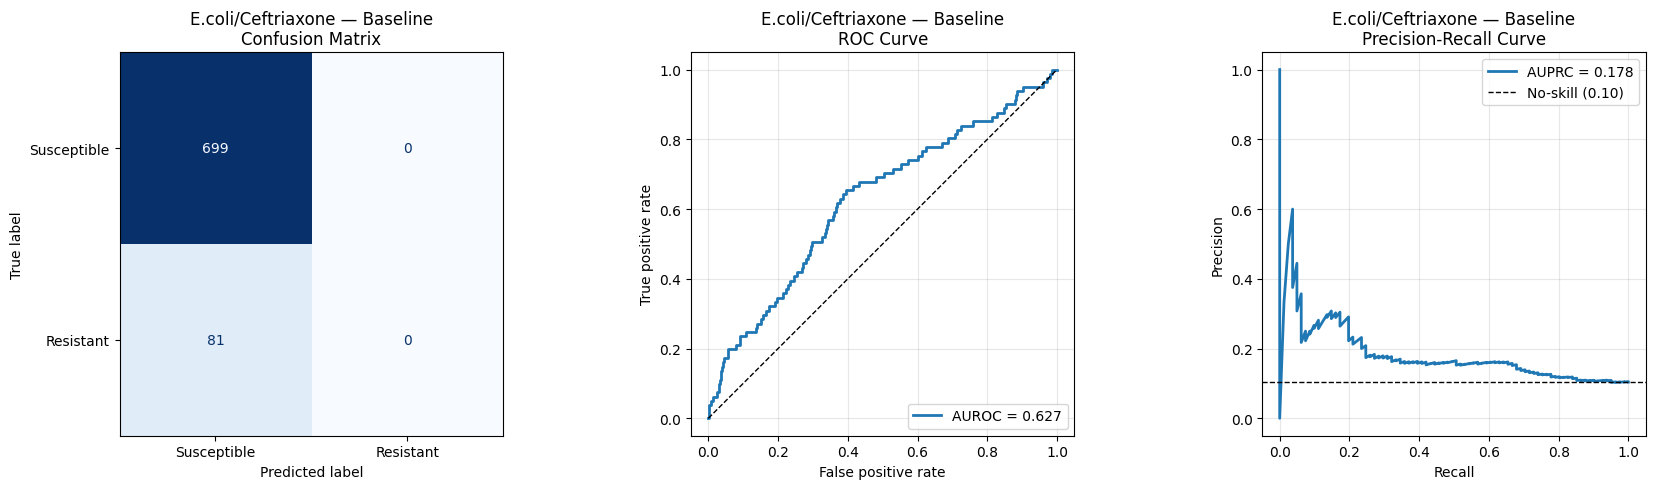

In [22]:
## Experiment 1-A - Zero-shot Baseline (E. coli)

print("--- Experiment 1-A : Zero-shot baseline ---")
ec_baseline = get_model_copy('e_coli_ceftriaxone')
ec_baseline.eval()

res = evaluate_model(
    ec_baseline, ec_X_test, ec_y_test,
    ec_X_train,  ec_y_train,
    label='E.coli/Ceftriaxone — Baseline'
)
res['model'] = 'e_coli_ceftriaxone'
res['experiment'] = 'Baseline'
ALL_RESULTS.append(res)

--- Experiment 1-B : Full fine-tune ---
  Full fine-tune  — trainable params: 566,336 / 566,336
  Epoch   1/50  train_loss=0.7023  val_loss=0.7117  val_acc=0.4783  lr=1.00e-05
  Epoch   2/50  train_loss=0.6549  val_loss=0.7410  val_acc=0.4348  lr=1.00e-05
  Epoch   3/50  train_loss=0.6474  val_loss=0.6386  val_acc=0.6522  lr=1.00e-05
  Epoch   4/50  train_loss=0.6369  val_loss=0.6496  val_acc=0.6196  lr=1.00e-05
  Epoch   5/50  train_loss=0.6435  val_loss=0.6730  val_acc=0.5652  lr=1.00e-05
  Epoch   6/50  train_loss=0.6236  val_loss=0.6107  val_acc=0.6848  lr=1.00e-05
  Epoch   7/50  train_loss=0.6198  val_loss=0.7562  val_acc=0.4239  lr=1.00e-05
  Epoch   8/50  train_loss=0.6118  val_loss=0.6410  val_acc=0.6413  lr=1.00e-05
  Epoch   9/50  train_loss=0.6329  val_loss=0.6652  val_acc=0.6413  lr=1.00e-05
  Epoch  10/50  train_loss=0.6217  val_loss=0.5673  val_acc=0.7500  lr=1.00e-05
  Epoch  11/50  train_loss=0.6024  val_loss=0.6255  val_acc=0.6630  lr=1.00e-05
  Epoch  12/50  train_lo

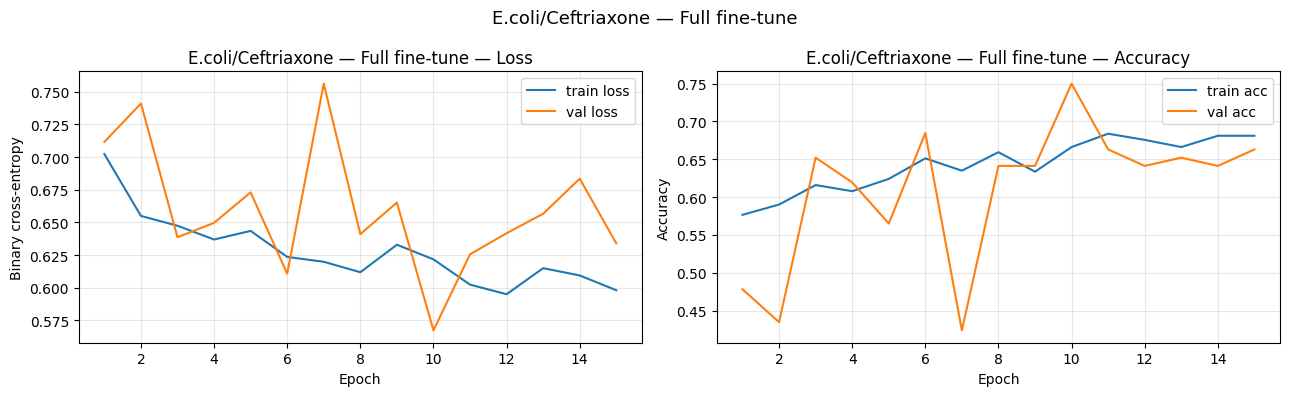


Confusion matrix:
[[675  24]
 [ 67  14]]
Balanced accuracy : 0.5693

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.91      0.97      0.94       699
  Resistant (1)       0.37      0.17      0.24        81

       accuracy                           0.88       780
      macro avg       0.64      0.57      0.59       780
   weighted avg       0.85      0.88      0.86       780

AUROC  (sklearn)  : 0.6472
AUPRC  (sklearn)  : 0.2243  (random baseline = 0.104)


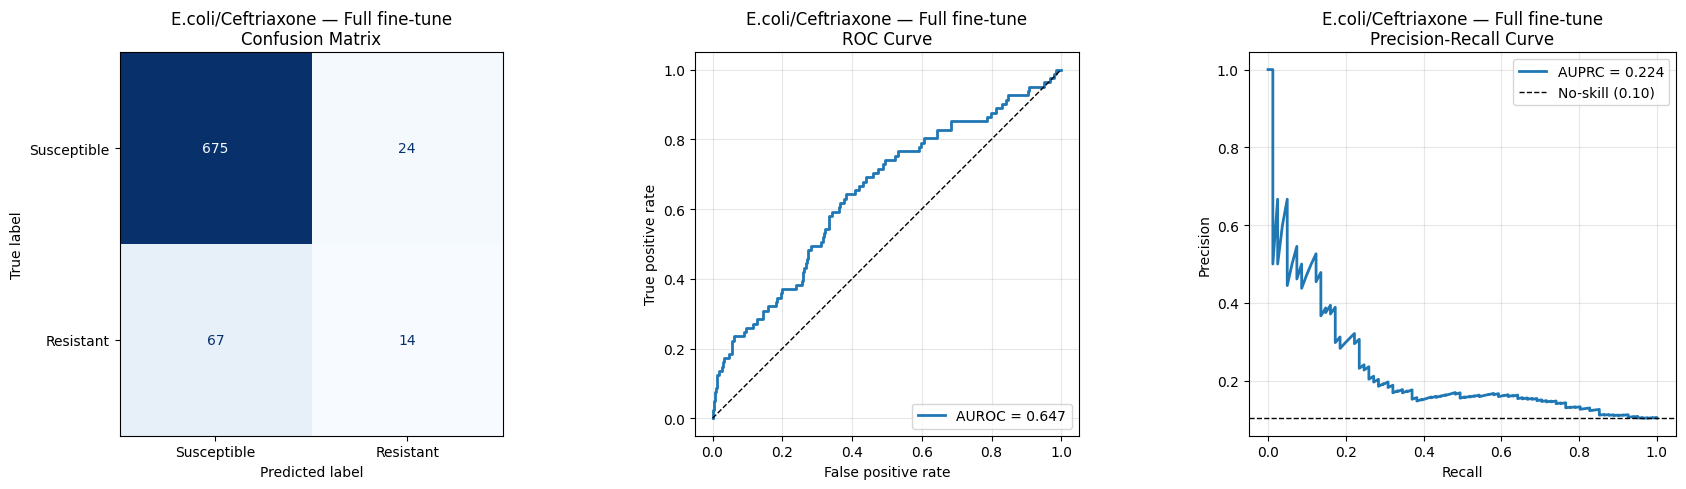

Saved: e_coli_ceftriaxone_full_ft.pt


In [23]:
## Experiment 1-B - Full fine-tune (E. coli)

print("--- Experiment 1-B : Full fine-tune ---")
ec_ft_full, ec_opt_full = strategy_full_finetune('e_coli_ceftriaxone')

hist_ec_full = train_model(
    ec_ft_full, ec_opt_full,
    ec_train_loader, ec_val_loader,
    label='E.coli/Ceftriaxone — Full fine-tune'
)
plot_history(hist_ec_full, label='E.coli/Ceftriaxone — Full fine-tune')

res = evaluate_model(
    ec_ft_full, ec_X_test, ec_y_test,
    ec_X_train, ec_y_train,
    label='E.coli/Ceftriaxone — Full fine-tune'
)
res['model'] = 'e_coli_ceftriaxone'
res['experiment'] = 'Full fine-tune'
ALL_RESULTS.append(res)

# Save fine-tuned weights
torch.save(ec_ft_full.state_dict(),
           os.path.join(PT_DIR, 'e_coli_ceftriaxone_full_ft.pt'))
print("Saved: e_coli_ceftriaxone_full_ft.pt")

--- Experiment 1-C : Partial unfreeze ---
  Partial unfreeze — trainable: 565,248  frozen: 1,088
  Epoch   1/50  train_loss=0.6980  val_loss=0.6631  val_acc=0.5761  lr=5.00e-06
  Epoch   2/50  train_loss=0.6705  val_loss=0.6888  val_acc=0.5326  lr=5.00e-06
  Epoch   3/50  train_loss=0.6532  val_loss=0.6214  val_acc=0.6630  lr=5.00e-06
  Epoch   4/50  train_loss=0.6353  val_loss=0.6975  val_acc=0.4891  lr=5.00e-06
  Epoch   5/50  train_loss=0.6267  val_loss=0.6763  val_acc=0.5109  lr=5.00e-06
  Epoch   6/50  train_loss=0.6484  val_loss=0.7047  val_acc=0.5109  lr=5.00e-06
  Epoch   7/50  train_loss=0.6425  val_loss=0.7035  val_acc=0.5217  lr=5.00e-07
  Epoch   8/50  train_loss=0.6182  val_loss=0.6806  val_acc=0.5217  lr=5.00e-07
  Early stopping at epoch 8 (best val_loss=0.6214)
  Best weights restored.


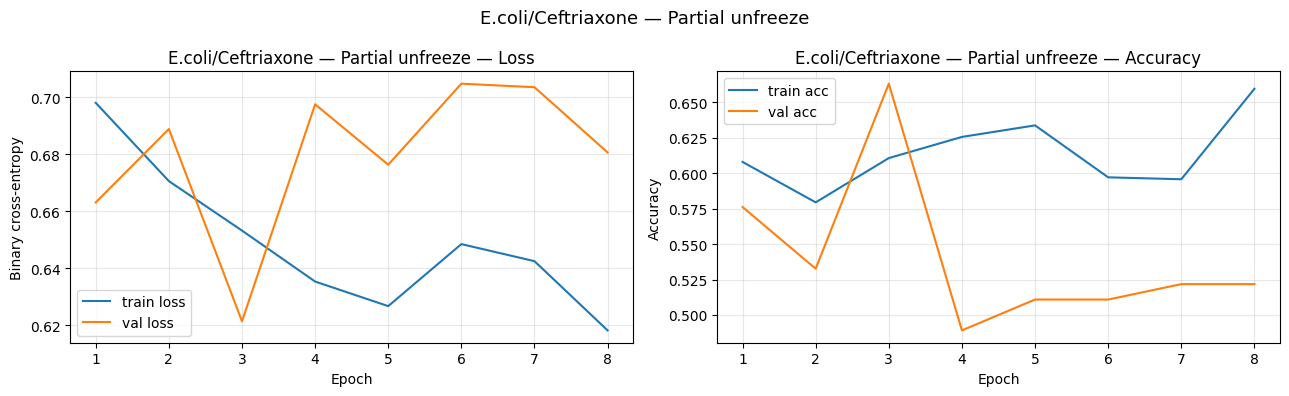


Confusion matrix:
[[633  66]
 [ 62  19]]
Balanced accuracy : 0.5701

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.91      0.91      0.91       699
  Resistant (1)       0.22      0.23      0.23        81

       accuracy                           0.84       780
      macro avg       0.57      0.57      0.57       780
   weighted avg       0.84      0.84      0.84       780

AUROC  (sklearn)  : 0.6309
AUPRC  (sklearn)  : 0.1882  (random baseline = 0.104)


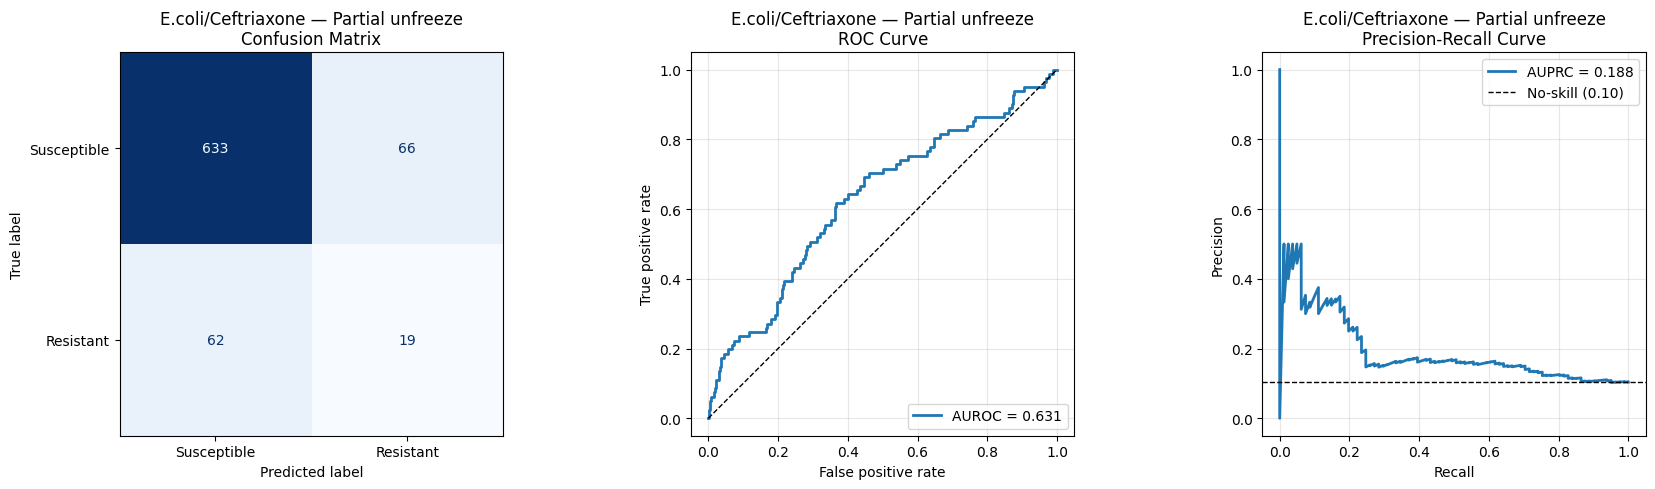

Saved: e_coli_ceftriaxone_partial_ft.pt


In [24]:
## Experiment 1-C - Partial unfreeze (E. coli)

print("--- Experiment 1-C : Partial unfreeze ---")
ec_ft_partial, ec_opt_partial = strategy_partial_unfreeze('e_coli_ceftriaxone')

hist_ec_partial = train_model(
    ec_ft_partial, ec_opt_partial,
    ec_train_loader, ec_val_loader,
    label='E.coli/Ceftriaxone — Partial unfreeze'
)
plot_history(hist_ec_partial, label='E.coli/Ceftriaxone — Partial unfreeze')

res = evaluate_model(
    ec_ft_partial, ec_X_test, ec_y_test,
    ec_X_train,    ec_y_train,
    label='E.coli/Ceftriaxone — Partial unfreeze'
)
res['model'] = 'e_coli_ceftriaxone'
res['experiment'] = 'Partial unfreeze'
ALL_RESULTS.append(res)

torch.save(ec_ft_partial.state_dict(),
           os.path.join(PT_DIR, 'e_coli_ceftriaxone_partial_ft.pt'))
print("Saved: e_coli_ceftriaxone_partial_ft.pt")

### Organism 2 - Klebiella pneumoniae/ Ceftriaxone

In [25]:
print("=" * 65)
print("ORGANISM : Klebsiella pneumoniae")
print("DRUG     : Ceftriaxone")
print("=" * 65)

KP_META = MODEL_META['k_pneumoniae_ceftriaxone']
(
    kp_train_loader, kp_val_loader, kp_test_loader,
    kp_X_test,  kp_y_test,
    kp_X_train, kp_y_train
) = build_splits(KP_META['species'], KP_META['drug'])

ORGANISM : Klebsiella pneumoniae
DRUG     : Ceftriaxone
  Species : Klebsiella pneumoniae
  Drug    : Ceftriaxone
  Train   :   297 samples | Resistant=45 (15.2%)
  Val     :    40 samples | Resistant=6 (15.0%)
  Test    :   526 samples | Resistant=34 (6.5%)


--- Experiment 2-A : Zero-shot baseline ---

Confusion matrix:
[[492   0]
 [ 34   0]]
Balanced accuracy : 0.5000

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.94      1.00      0.97       492
  Resistant (1)       0.00      0.00      0.00        34

       accuracy                           0.94       526
      macro avg       0.47      0.50      0.48       526
   weighted avg       0.87      0.94      0.90       526

AUROC  (sklearn)  : 0.6995
AUPRC  (sklearn)  : 0.1813  (random baseline = 0.065)


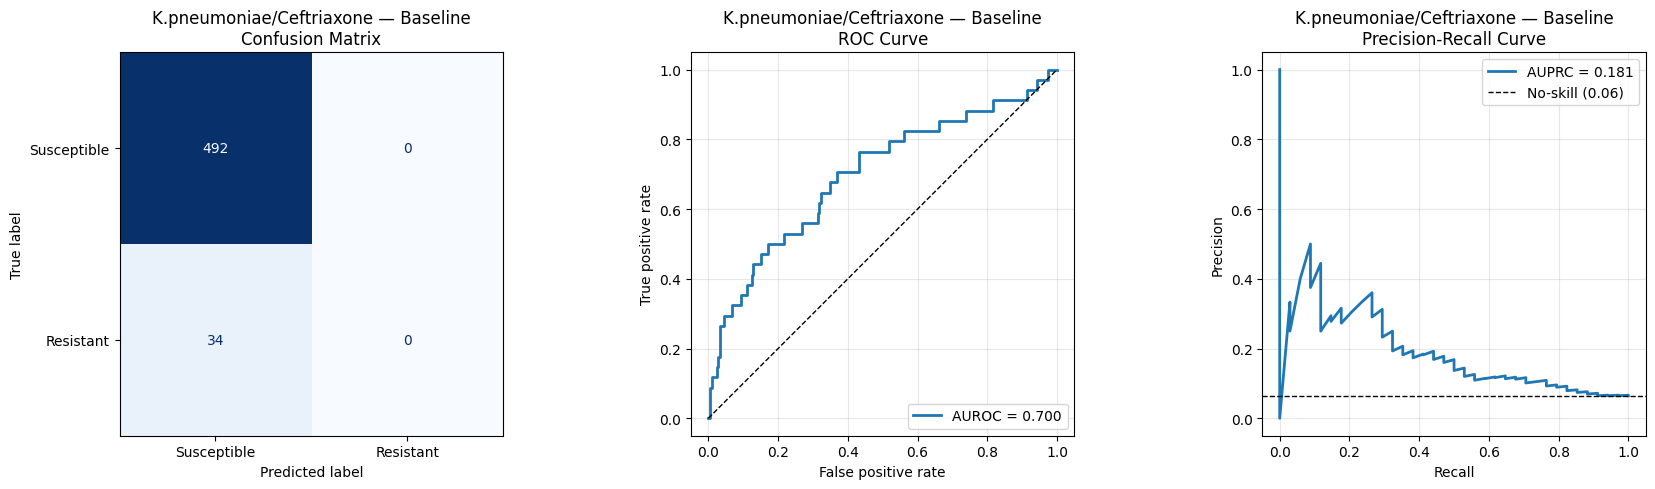

In [26]:
## Experiment 2-A - Zero-shot baseline (K. pneumoniae)

print("--- Experiment 2-A : Zero-shot baseline ---")
kp_baseline = get_model_copy('k_pneumoniae_ceftriaxone')
kp_baseline.eval()

res = evaluate_model(
    kp_baseline, kp_X_test, kp_y_test,
    kp_X_train,  kp_y_train,
    label='K.pneumoniae/Ceftriaxone — Baseline'
)
res['model'] = 'k_pneumoniae_ceftriaxone'
res['experiment'] = 'Baseline'
ALL_RESULTS.append(res)

--- Experiment 2-B : Full fine-tune ---
  Full fine-tune  — trainable params: 566,336 / 566,336
  Epoch   1/50  train_loss=0.7577  val_loss=0.5555  val_acc=0.8500  lr=1.00e-05
  Epoch   2/50  train_loss=0.6864  val_loss=0.6106  val_acc=0.8250  lr=1.00e-05
  Epoch   3/50  train_loss=0.7028  val_loss=0.6650  val_acc=0.5500  lr=1.00e-05
  Epoch   4/50  train_loss=0.6872  val_loss=0.7137  val_acc=0.3750  lr=1.00e-05
  Epoch   5/50  train_loss=0.6886  val_loss=0.6546  val_acc=0.6500  lr=1.00e-06
  Epoch   6/50  train_loss=0.6878  val_loss=0.6589  val_acc=0.6250  lr=1.00e-06
  Early stopping at epoch 6 (best val_loss=0.5555)
  Best weights restored.


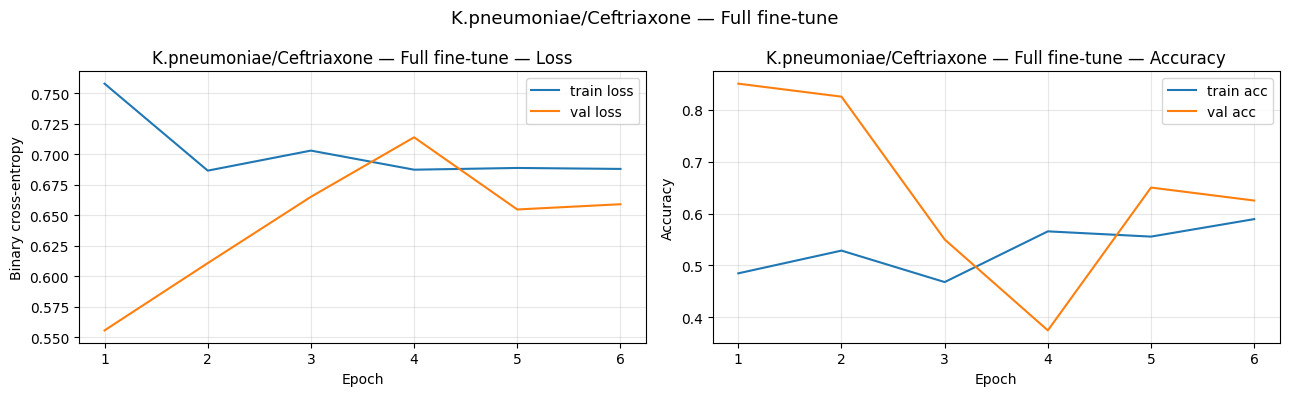


Confusion matrix:
[[491   1]
 [ 34   0]]
Balanced accuracy : 0.4990

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.94      1.00      0.97       492
  Resistant (1)       0.00      0.00      0.00        34

       accuracy                           0.93       526
      macro avg       0.47      0.50      0.48       526
   weighted avg       0.87      0.93      0.90       526

AUROC  (sklearn)  : 0.6947
AUPRC  (sklearn)  : 0.1862  (random baseline = 0.065)


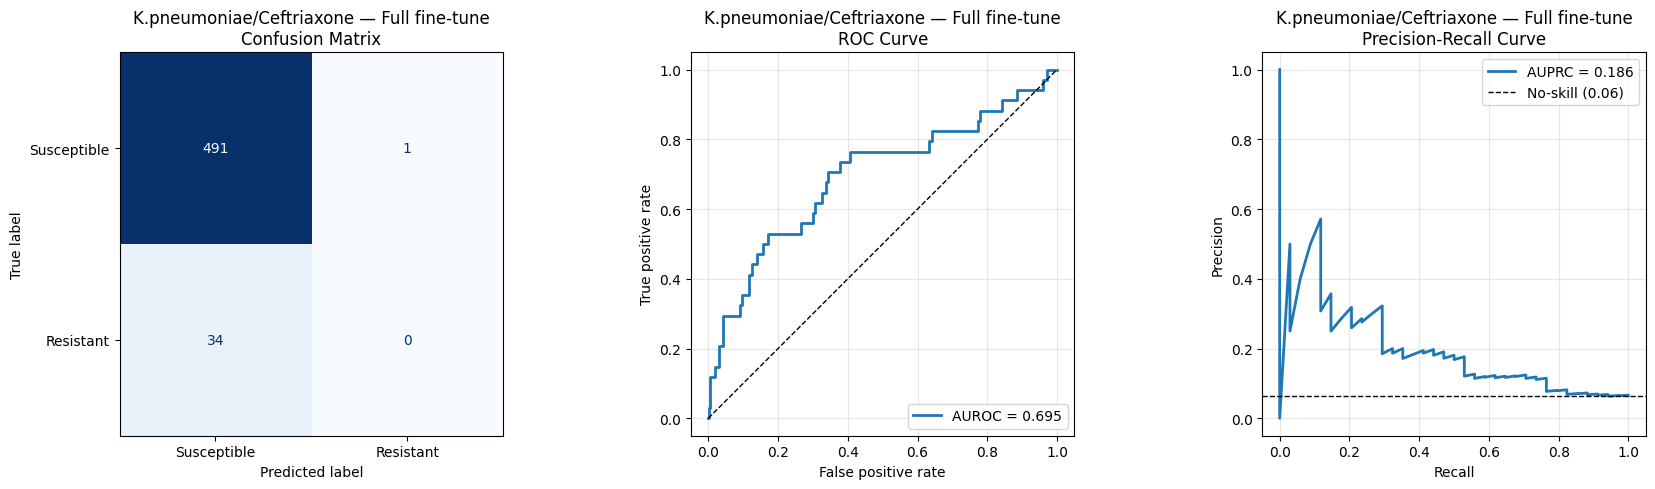

Saved: k_pneumoniae_ceftriaxone_full_ft.pt


In [27]:
## Experiment 2-B - Full fine-tune (K. pneumoniae)

print("--- Experiment 2-B : Full fine-tune ---")
kp_ft_full, kp_opt_full = strategy_full_finetune('k_pneumoniae_ceftriaxone')

hist_kp_full = train_model(
    kp_ft_full, kp_opt_full,
    kp_train_loader, kp_val_loader,
    label='K.pneumoniae/Ceftriaxone — Full fine-tune'
)
plot_history(hist_kp_full, label='K.pneumoniae/Ceftriaxone — Full fine-tune')

res = evaluate_model(
    kp_ft_full, kp_X_test, kp_y_test,
    kp_X_train, kp_y_train,
    label='K.pneumoniae/Ceftriaxone — Full fine-tune'
)
res['model'] = 'k_pneumoniae_ceftriaxone'
res['experiment'] = 'Full fine-tune'
ALL_RESULTS.append(res)

torch.save(kp_ft_full.state_dict(),
           os.path.join(PT_DIR, 'k_pneumoniae_ceftriaxone_full_ft.pt'))
print("Saved: k_pneumoniae_ceftriaxone_full_ft.pt")

--- Experiment 2-C : Partial unfreeze ---
  Partial unfreeze — trainable: 565,248  frozen: 1,088
  Epoch   1/50  train_loss=0.7924  val_loss=0.5062  val_acc=0.8500  lr=5.00e-06
  Epoch   2/50  train_loss=0.7031  val_loss=0.5369  val_acc=0.8500  lr=5.00e-06
  Epoch   3/50  train_loss=0.7176  val_loss=0.5727  val_acc=0.8500  lr=5.00e-06
  Epoch   4/50  train_loss=0.6955  val_loss=0.5970  val_acc=0.8500  lr=5.00e-06
  Epoch   5/50  train_loss=0.6671  val_loss=0.5821  val_acc=0.8500  lr=5.00e-07
  Epoch   6/50  train_loss=0.6849  val_loss=0.5829  val_acc=0.8500  lr=5.00e-07
  Early stopping at epoch 6 (best val_loss=0.5062)
  Best weights restored.


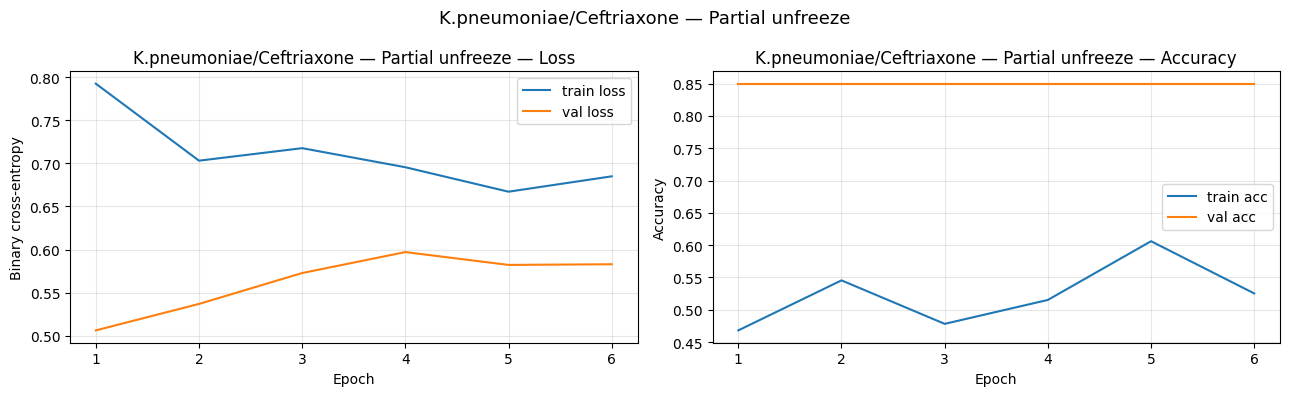


Confusion matrix:
[[492   0]
 [ 34   0]]
Balanced accuracy : 0.5000

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.94      1.00      0.97       492
  Resistant (1)       0.00      0.00      0.00        34

       accuracy                           0.94       526
      macro avg       0.47      0.50      0.48       526
   weighted avg       0.87      0.94      0.90       526

AUROC  (sklearn)  : 0.6985
AUPRC  (sklearn)  : 0.1806  (random baseline = 0.065)


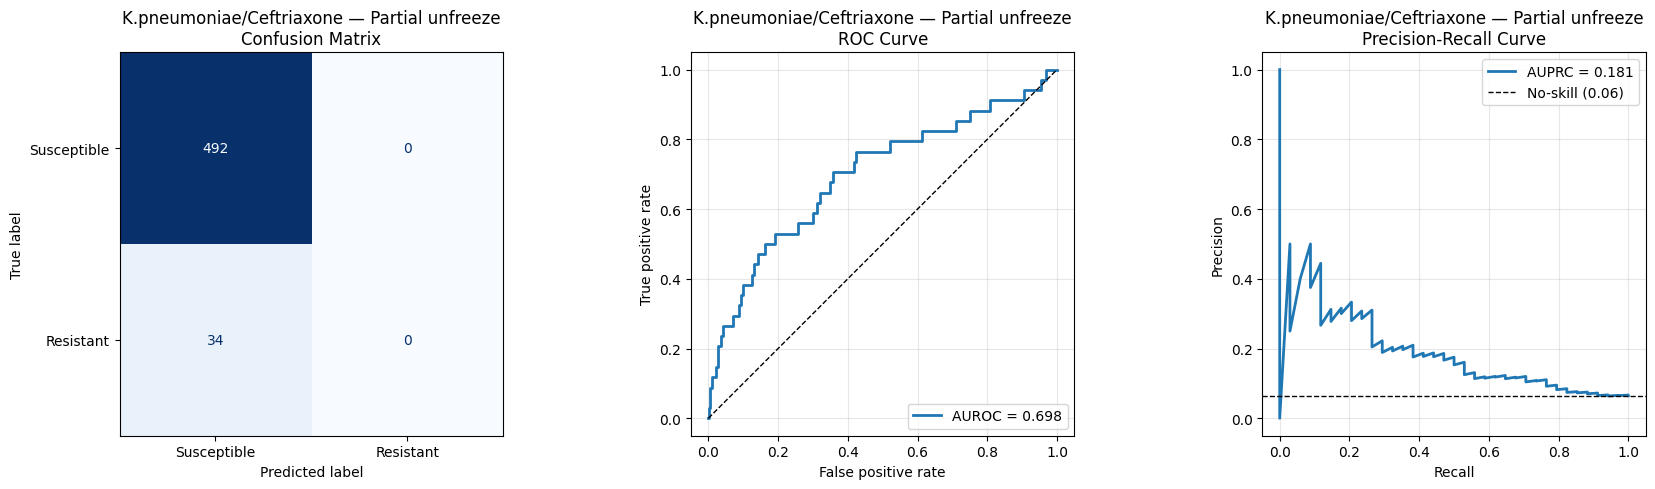

Saved: k_pneumoniae_ceftriaxone_partial_ft.pt


In [28]:
## Experiment 2-C - Partial unfreeze (K. pneumoniae)

print("--- Experiment 2-C : Partial unfreeze ---")
kp_ft_partial, kp_opt_partial = strategy_partial_unfreeze('k_pneumoniae_ceftriaxone')

hist_kp_partial = train_model(
    kp_ft_partial, kp_opt_partial,
    kp_train_loader, kp_val_loader,
    label='K.pneumoniae/Ceftriaxone — Partial unfreeze'
)
plot_history(hist_kp_partial, label='K.pneumoniae/Ceftriaxone — Partial unfreeze')

res = evaluate_model(
    kp_ft_partial, kp_X_test, kp_y_test,
    kp_X_train,    kp_y_train,
    label='K.pneumoniae/Ceftriaxone — Partial unfreeze'
)
res['model'] = 'k_pneumoniae_ceftriaxone'
res['experiment'] = 'Partial unfreeze'
ALL_RESULTS.append(res)

torch.save(kp_ft_partial.state_dict(),
           os.path.join(PT_DIR, 'k_pneumoniae_ceftriaxone_partial_ft.pt'))
print("Saved: k_pneumoniae_ceftriaxone_partial_ft.pt")

### Organism 3 - Staphylococcus aureus/ Oxacillin

In [29]:
print("=" * 65)
print("ORGANISM : Staphylococcus aureus")
print("DRUG     : Oxacillin")
print("=" * 65)

SA_META = MODEL_META['s_aureus_oxacillin']
(
    sa_train_loader, sa_val_loader, sa_test_loader,
    sa_X_test,  sa_y_test,
    sa_X_train, sa_y_train
) = build_splits(SA_META['species'], SA_META['drug'])

ORGANISM : Staphylococcus aureus
DRUG     : Oxacillin
  Species : Staphylococcus aureus
  Drug    : Oxacillin
  Train   :   573 samples | Resistant=35 (6.1%)
  Val     :    83 samples | Resistant=2 (2.4%)
  Test    :   450 samples | Resistant=37 (8.2%)


--- Experiment 3-A : Zero-shot baseline ---

Confusion matrix:
[[403  10]
 [ 36   1]]
Balanced accuracy : 0.5014

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.92      0.98      0.95       413
  Resistant (1)       0.09      0.03      0.04        37

       accuracy                           0.90       450
      macro avg       0.50      0.50      0.49       450
   weighted avg       0.85      0.90      0.87       450

AUROC  (sklearn)  : 0.7032
AUPRC  (sklearn)  : 0.1272  (random baseline = 0.082)


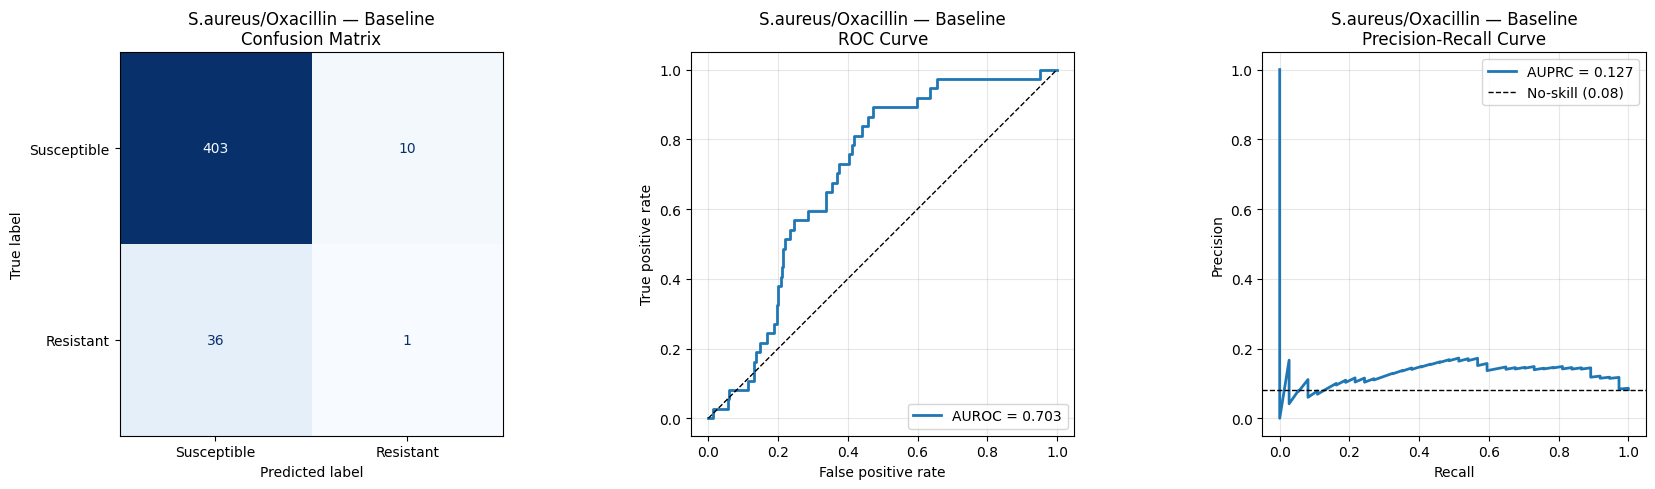

In [30]:
## Experiment 3-A - Zero-shot baseline (S. aureus)

print("--- Experiment 3-A : Zero-shot baseline ---")
sa_baseline = get_model_copy('s_aureus_oxacillin')
sa_baseline.eval()

res = evaluate_model(
    sa_baseline, sa_X_test, sa_y_test,
    sa_X_train,  sa_y_train,
    label='S.aureus/Oxacillin — Baseline'
)
res['model'] = 's_aureus_oxacillin'
res['experiment'] = 'Baseline'
ALL_RESULTS.append(res)

--- Experiment 3-B : Full fine-tune ---
  Full fine-tune  — trainable params: 566,336 / 566,336
  Epoch   1/50  train_loss=0.6821  val_loss=0.7247  val_acc=0.4337  lr=1.00e-05
  Epoch   2/50  train_loss=0.6625  val_loss=0.8423  val_acc=0.1325  lr=1.00e-05
  Epoch   3/50  train_loss=0.6624  val_loss=0.8227  val_acc=0.2169  lr=1.00e-05
  Epoch   4/50  train_loss=0.6305  val_loss=0.8272  val_acc=0.2169  lr=1.00e-05
  Epoch   5/50  train_loss=0.6517  val_loss=0.6026  val_acc=0.7470  lr=1.00e-05
  Epoch   6/50  train_loss=0.6479  val_loss=0.6274  val_acc=0.7108  lr=1.00e-05
  Epoch   7/50  train_loss=0.6340  val_loss=0.6127  val_acc=0.7349  lr=1.00e-05
  Epoch   8/50  train_loss=0.6211  val_loss=0.6722  val_acc=0.6024  lr=1.00e-05
  Epoch   9/50  train_loss=0.6128  val_loss=0.7823  val_acc=0.3855  lr=1.00e-06
  Epoch  10/50  train_loss=0.6267  val_loss=0.7505  val_acc=0.4940  lr=1.00e-06
  Early stopping at epoch 10 (best val_loss=0.6026)
  Best weights restored.


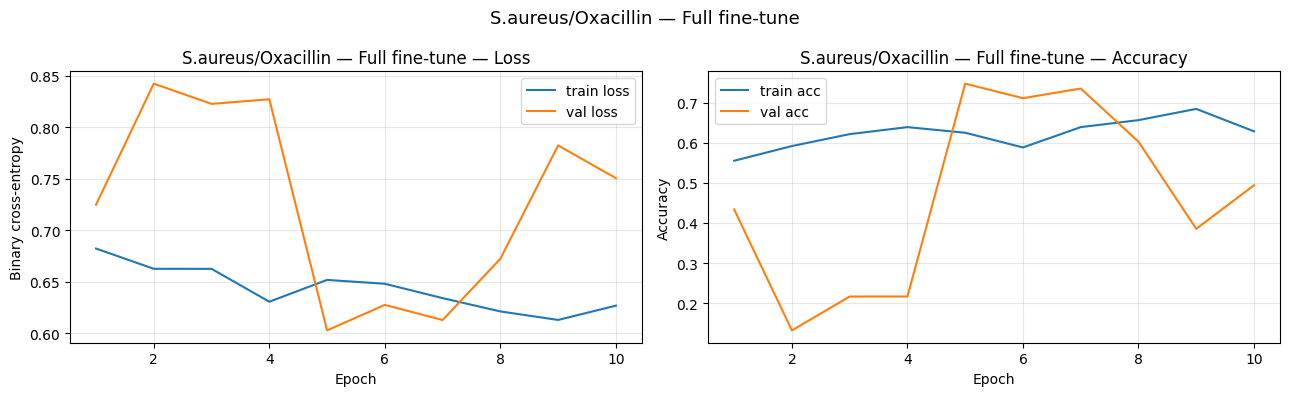


Confusion matrix:
[[399  14]
 [ 35   2]]
Balanced accuracy : 0.5101

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.92      0.97      0.94       413
  Resistant (1)       0.12      0.05      0.08        37

       accuracy                           0.89       450
      macro avg       0.52      0.51      0.51       450
   weighted avg       0.85      0.89      0.87       450

AUROC  (sklearn)  : 0.7069
AUPRC  (sklearn)  : 0.1339  (random baseline = 0.082)


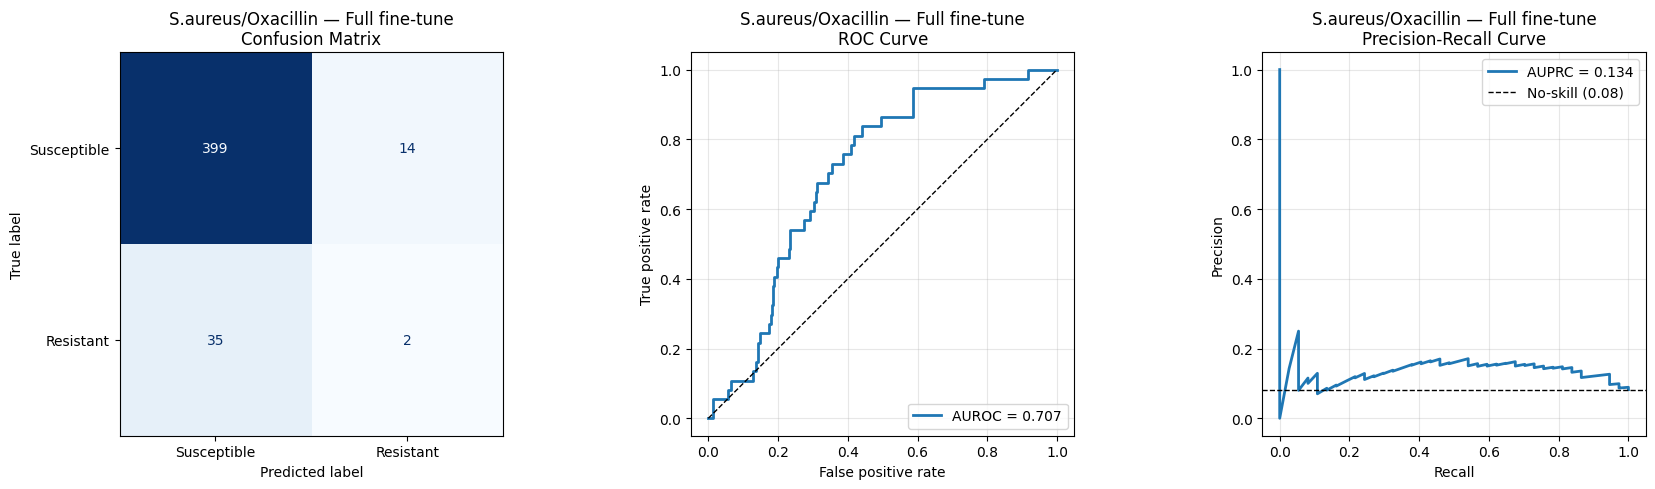

Saved: s_aureus_oxacillin_full_ft.pt


In [31]:
## Experiment 3-B - Full fine-tune (S. aureus)

print("--- Experiment 3-B : Full fine-tune ---")
sa_ft_full, sa_opt_full = strategy_full_finetune('s_aureus_oxacillin')

hist_sa_full = train_model(
    sa_ft_full, sa_opt_full,
    sa_train_loader, sa_val_loader,
    label='S.aureus/Oxacillin — Full fine-tune'
)
plot_history(hist_sa_full, label='S.aureus/Oxacillin — Full fine-tune')

res = evaluate_model(
    sa_ft_full, sa_X_test, sa_y_test,
    sa_X_train, sa_y_train,
    label='S.aureus/Oxacillin — Full fine-tune'
)
res['model'] = 's_aureus_oxacillin'
res['experiment'] = 'Full fine-tune'
ALL_RESULTS.append(res)

torch.save(sa_ft_full.state_dict(),
           os.path.join(PT_DIR, 's_aureus_oxacillin_full_ft.pt'))
print("Saved: s_aureus_oxacillin_full_ft.pt")

--- Experiment 3-C : Partial unfreeze ---
  Partial unfreeze — trainable: 565,248  frozen: 1,088
  Epoch   1/50  train_loss=0.6701  val_loss=0.6919  val_acc=0.5301  lr=5.00e-06
  Epoch   2/50  train_loss=0.6693  val_loss=0.7267  val_acc=0.4337  lr=5.00e-06
  Epoch   3/50  train_loss=0.6339  val_loss=0.7215  val_acc=0.4819  lr=5.00e-06
  Epoch   4/50  train_loss=0.6425  val_loss=0.7161  val_acc=0.5181  lr=5.00e-06
  Epoch   5/50  train_loss=0.6482  val_loss=0.7574  val_acc=0.4217  lr=5.00e-07
  Epoch   6/50  train_loss=0.6424  val_loss=0.7596  val_acc=0.4217  lr=5.00e-07
  Early stopping at epoch 6 (best val_loss=0.6919)
  Best weights restored.


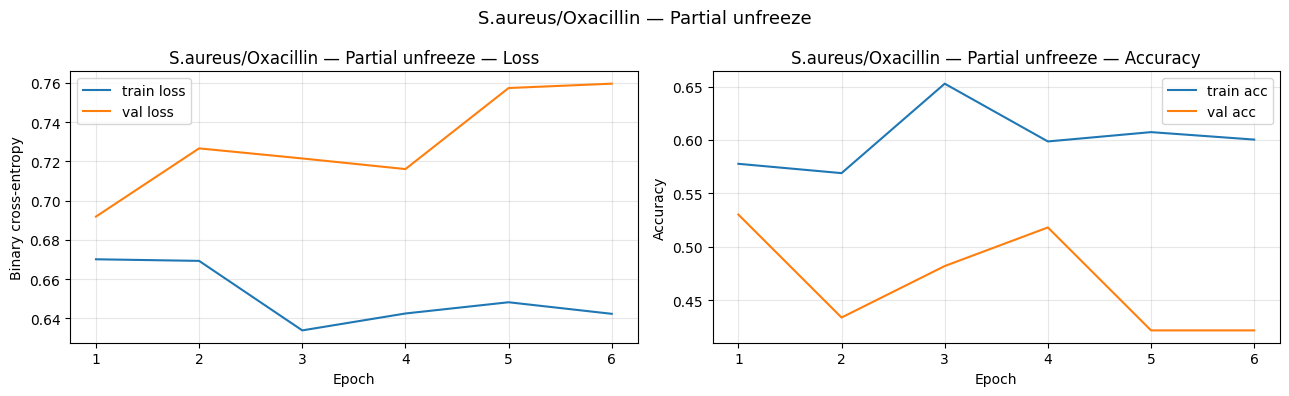


Confusion matrix:
[[378  35]
 [ 33   4]]
Balanced accuracy : 0.5117

Classification report:
                 precision    recall  f1-score   support

Susceptible (0)       0.92      0.92      0.92       413
  Resistant (1)       0.10      0.11      0.11        37

       accuracy                           0.85       450
      macro avg       0.51      0.51      0.51       450
   weighted avg       0.85      0.85      0.85       450

AUROC  (sklearn)  : 0.7062
AUPRC  (sklearn)  : 0.1295  (random baseline = 0.082)


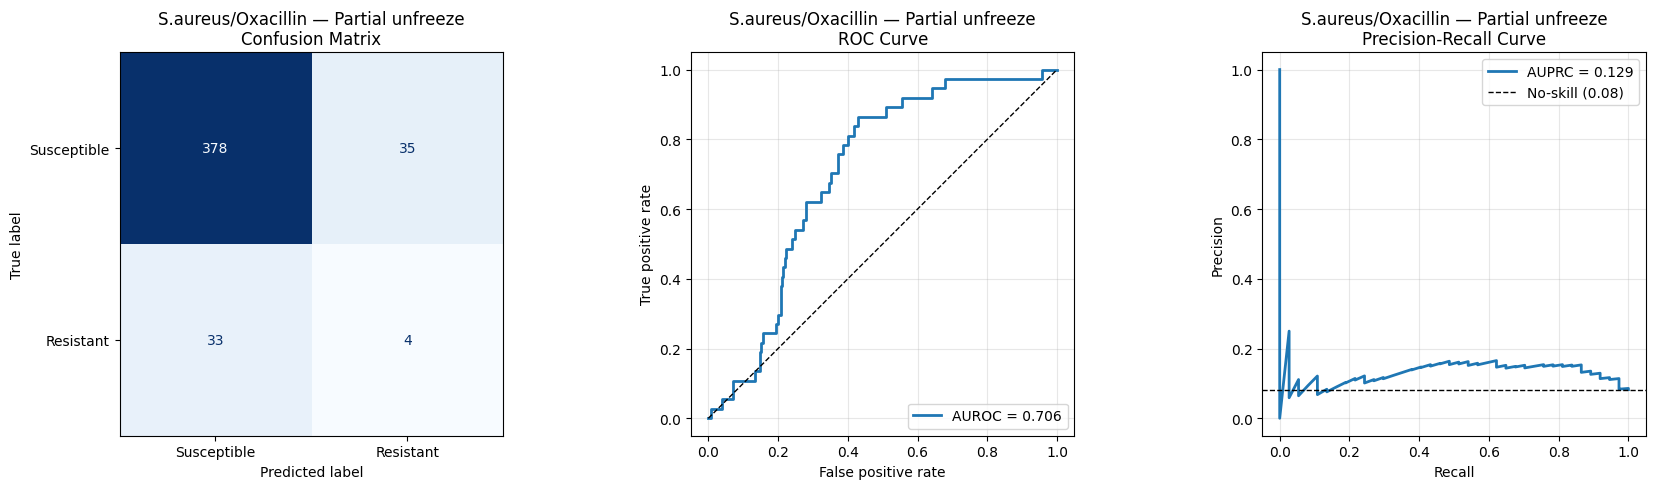

Saved: s_aureus_oxacillin_partial_ft.pt


In [32]:
## Experiment 3-C - Partial unfreeze (S. aureus)

print("--- Experiment 3-C : Partial unfreeze ---")
sa_ft_partial, sa_opt_partial = strategy_partial_unfreeze('s_aureus_oxacillin')

hist_sa_partial = train_model(
    sa_ft_partial, sa_opt_partial,
    sa_train_loader, sa_val_loader,
    label='S.aureus/Oxacillin — Partial unfreeze'
)
plot_history(hist_sa_partial, label='S.aureus/Oxacillin — Partial unfreeze')

res = evaluate_model(
    sa_ft_partial, sa_X_test, sa_y_test,
    sa_X_train,    sa_y_train,
    label='S.aureus/Oxacillin — Partial unfreeze'
)
res['model'] = 's_aureus_oxacillin'
res['experiment'] = 'Partial unfreeze'
ALL_RESULTS.append(res)

torch.save(sa_ft_partial.state_dict(),
           os.path.join(PT_DIR, 's_aureus_oxacillin_partial_ft.pt'))
print("Saved: s_aureus_oxacillin_partial_ft.pt")

## Summary & Comparison

In [33]:
results_df = pd.DataFrame(ALL_RESULTS)

col_order = [
    'model', 'experiment',
    'balanced_acc', 'accuracy',
    'precision', 'recall',
    'auroc_sk', 'auprc_sk',
    'tp', 'fp', 'tn', 'fn'
]
results_df = results_df[[c for c in col_order if c in results_df.columns]]

print("Full results table (PyTorch pipeline):")
display(results_df.set_index(['model', 'experiment']))

results_df.to_csv('finetune_pytorch_results.csv', index=False)
print("\nSaved → finetune_pytorch_results.csv")

Full results table (PyTorch pipeline):


balanced_acc  accuracy  precision  \
model                    experiment                                            
e_coli_ceftriaxone       Baseline                0.5000    0.8962     0.0000   
                         Full fine-tune          0.5693    0.8833     0.3684   
                         Partial unfreeze        0.5701    0.8359     0.2235   
k_pneumoniae_ceftriaxone Baseline                0.5000    0.9354     0.0000   
                         Full fine-tune          0.4990    0.9335     0.0000   
                         Partial unfreeze        0.5000    0.9354     0.0000   
s_aureus_oxacillin       Baseline                0.5014    0.8978     0.0909   
                         Full fine-tune          0.5101    0.8911     0.1250   
                         Partial unfreeze        0.5117    0.8489     0.1026   

                                           recall  auroc_sk  auprc_sk  tp  fp  \
model                    experiment                                             
e_coli_ceftriaxone       Baseline          0.0000    0.6273    0.1784   0   0   
                         Full fine-tune    0.1728    0.6472    0.2243  14  24   
                         Partial unfreeze  0.2346    0.6309    0.1882  19  66   
k_pneumoniae_ceftriaxone Baseline          0.0000    0.6995    0.1813   0   0   
                         Full fine-tune    0.0000    0.6947    0.1862   0   1   
                         Partial unfreeze  0.0000    0.6985    0.1806   0   0   
s_aureus_oxacillin       Baseline          0.0270    0.7032    0.1272   1  10   
                         Full fine-tune    0.0541    0.7069    0.1339   2  14   
                         Partial unfreeze  0.1081    0.7062    0.1295   4  35   

                                            tn  fn  
model                    experiment                 
e_coli_ceftriaxone       Baseline          699  81  
                         Full fine-tune    675  67  
                         Partial unfreeze  633  62  
k_pneumoniae_ceftriaxone Baseline          492  34  
                         Full fine-tune    491  34  
                         Partial unfreeze  492  34  
s_aureus_oxacillin       Baseline          403  36  
                         Full fine-tune    399  35  
                         Partial unfreeze  378  33


Saved → finetune_pytorch_results.csv


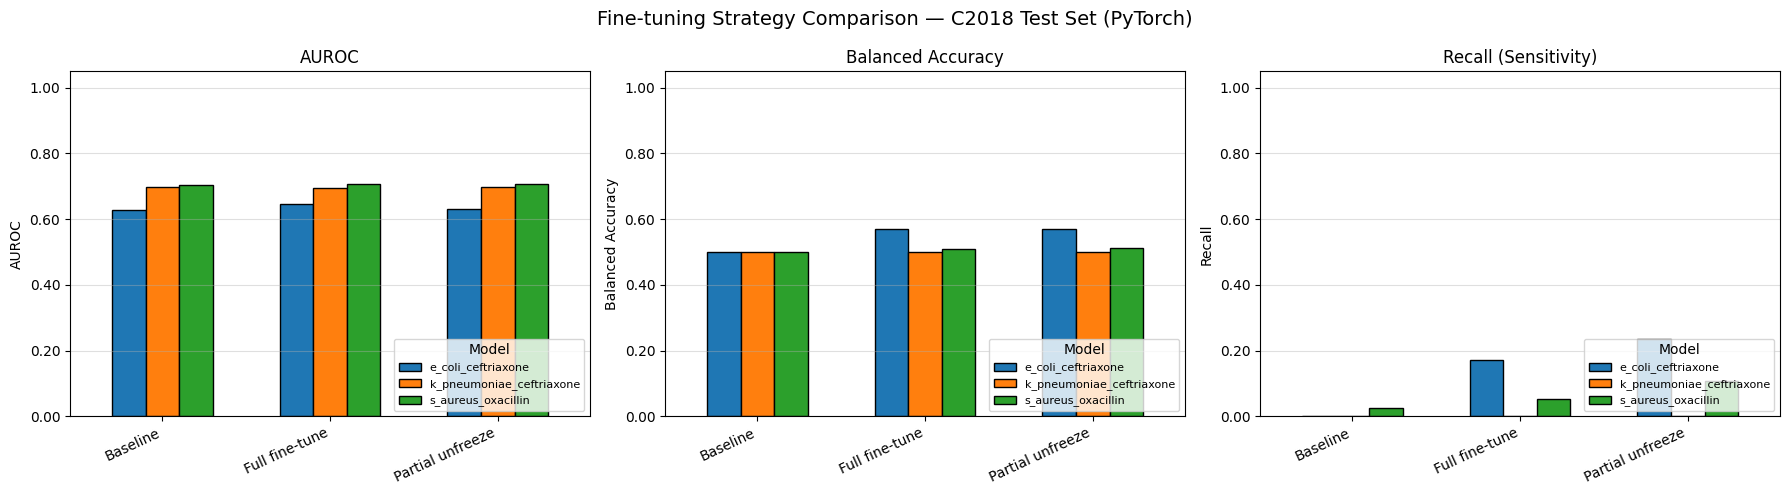

In [34]:
## Visula Comparison bar charts

import matplotlib.ticker as mticker

results_df = results_df.drop_duplicates(subset=['experiment', 'model'], keep='last')

pivot_auc    = results_df.pivot(index='experiment', columns='model', values='auroc_sk')
pivot_bal    = results_df.pivot(index='experiment', columns='model', values='balanced_acc')
pivot_recall = results_df.pivot(index='experiment', columns='model', values='recall')

exp_order = ['Baseline', 'Full fine-tune', 'Partial unfreeze']
pivot_auc    = pivot_auc.reindex(exp_order)
pivot_bal    = pivot_bal.reindex(exp_order)
pivot_recall = pivot_recall.reindex(exp_order)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, pivot, title, ylabel in zip(
    axes,
    [pivot_auc, pivot_bal, pivot_recall],
    ['AUROC', 'Balanced Accuracy', 'Recall (Sensitivity)'],
    ['AUROC', 'Balanced Accuracy', 'Recall']
):
    pivot.plot(kind='bar', ax=ax, edgecolor='black', width=0.6)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('')
    ax.set_xticklabels(pivot.index, rotation=25, ha='right')
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))
    ax.legend(title='Model', loc='lower right', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=0.4)

plt.suptitle('Fine-tuning Strategy Comparison — C2018 Test Set (PyTorch)', fontsize=14)
plt.tight_layout()
plt.savefig('finetune_pytorch_comparison_bars.png', bbox_inches='tight')
plt.show()